# Damped Vibration - Under-damping and Over-damping (不足減衰・過減衰)

A single-degree-of-freedom mass-spring-damper system is governed by:

$$m\ddot{x} + c\dot{x} + kx = 0$$

Defining the **natural frequency** $\omega_n=\sqrt{k/m}$ and **damping ratio** $\zeta = \dfrac{c}{2\sqrt{km}} = \dfrac{c}{c_{cr}}$, the character of the response depends entirely on $\zeta$:

| Regime | Condition | Behaviour |
|---|---|---|
| Underdamped | $0<\zeta<1$ | Oscillates, decaying envelope $e^{-\zeta\omega_n t}$ |
| Critically damped | $\zeta=1$ | Fastest return to equilibrium with no oscillation |
| **Overdamped** | $\zeta>1$ | No oscillation, slow exponential decay |

Reference: [Wikipedia - Damping ratio](https://en.wikipedia.org/wiki/Damping_ratio)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

class DampedVibration:
    # Free vibration of a single-DOF mass-spring-damper: m*x'' + c*x' + k*x = 0

    def __init__(self, m, k, c, x0=1.0, v0=0.0):
        # INPUT INITIAL INFORMATION
        #   m  : mass [kg]
        #   k  : spring stiffness [N/m]
        #   c  : damping coefficient [N.s/m]
        #   x0 : initial displacement [m]
        #   v0 : initial velocity [m/s]
        self.m, self.k, self.c = m, k, c
        self.x0, self.v0 = x0, v0
        self.wn = np.sqrt(k/m)                 # natural frequency [rad/s]
        self.zeta = c/(2*np.sqrt(k*m))          # damping ratio
        self.regime = ('underdamped' if self.zeta < 1
                        else 'critically damped' if self.zeta == 1
                        else 'overdamped')

    def x(self, t):
        t = np.asarray(t, dtype=float)
        wn, zeta, x0, v0 = self.wn, self.zeta, self.x0, self.v0
        if self.zeta < 1:
            # underdamped: decaying oscillation at damped frequency wd
            wd = wn*np.sqrt(1-zeta**2)
            return np.exp(-zeta*wn*t)*(x0*np.cos(wd*t) + ((v0+zeta*wn*x0)/wd)*np.sin(wd*t))
        elif self.zeta == 1:
            # critically damped
            return (x0 + (v0+wn*x0)*t)*np.exp(-wn*t)
        else:
            # overdamped: sum of two decaying exponentials
            r1 = -zeta*wn + wn*np.sqrt(zeta**2-1)
            r2 = -zeta*wn - wn*np.sqrt(zeta**2-1)
            C1 = (v0 - x0*r2)/(r1-r2)
            C2 = x0 - C1
            return C1*np.exp(r1*t) + C2*np.exp(r2*t)

    def verify_numeric(self, t):
        # cross-check the closed-form x(t) against direct numerical ODE integration
        def rhs(tt, y):
            xx, vv = y
            return [vv, -(self.c/self.m)*vv - (self.k/self.m)*xx]
        sol = solve_ivp(rhs, [t[0], t[-1]], [self.x0, self.v0], t_eval=t, rtol=1e-10, atol=1e-12)
        return sol.y[0]

### Sample: m = 1 kg, k = 100 N/m (ωn = 10 rad/s), x0 = 0.1 m, v0 = 0

Two damping coefficients are compared:
- **Underdamped**: c = 5 N·s/m -> ζ = 0.25
- **Overdamped**: c = 50 N·s/m -> ζ = 2.5

The closed-form solution is cross-checked against `scipy.integrate.solve_ivp` - the maximum discrepancy is reported for each case (should be ~machine precision).

In [2]:
m, k = 1.0, 100.0
x0, v0 = 0.1, 0.0
t = np.linspace(0, 2, 1000)

under = DampedVibration(m, k, c=5, x0=x0, v0=v0)
over  = DampedVibration(m, k, c=50, x0=x0, v0=v0)

for label, sysm in [('Underdamped', under), ('Overdamped', over)]:
    x_analytic = sysm.x(t)
    x_numeric = sysm.verify_numeric(t)
    err = np.max(np.abs(x_analytic-x_numeric))
    print(f"{label:12s}: zeta={sysm.zeta:.3f}, wn={sysm.wn:.3f} rad/s, "
          f"max |analytic-numeric| = {err:.2e}")

Underdamped : zeta=0.250, wn=10.000 rad/s, max |analytic-numeric| = 3.30e-12
Overdamped  : zeta=2.500, wn=10.000 rad/s, max |analytic-numeric| = 1.90e-12


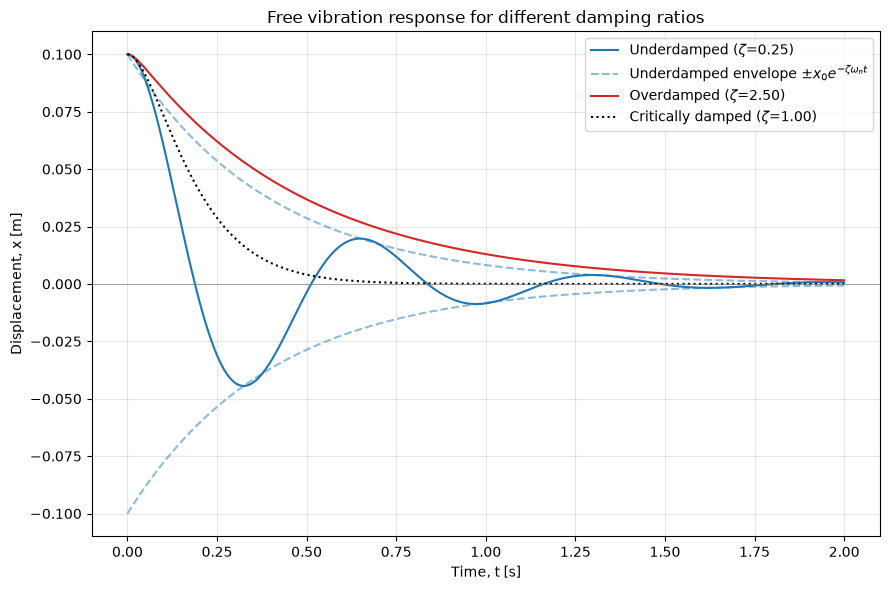

In [3]:
fig, ax = plt.subplots(figsize=(9,6))
ax.plot(t, under.x(t), label=f'Underdamped ($\\zeta$={under.zeta:.2f})', color='C0')
ax.plot(t, under.x0*np.exp(-under.zeta*under.wn*t), '--', color='C0', alpha=0.5,
        label=r'Underdamped envelope $\pm x_0 e^{-\zeta\omega_n t}$')
ax.plot(t, -under.x0*np.exp(-under.zeta*under.wn*t), '--', color='C0', alpha=0.5)
ax.plot(t, over.x(t), label=f'Overdamped ($\\zeta$={over.zeta:.2f})', color='C3')

crit = DampedVibration(m, k, c=2*np.sqrt(k*m), x0=x0, v0=v0)
ax.plot(t, crit.x(t), label=f'Critically damped ($\\zeta$={crit.zeta:.2f})', color='k', ls=':')

ax.axhline(color='gray', lw=0.5)
ax.set_xlabel('Time, t [s]')
ax.set_ylabel('Displacement, x [m]')
ax.set_title('Free vibration response for different damping ratios')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Reference :
1. [Wikipedia - Damping ratio](https://en.wikipedia.org/wiki/Damping_ratio)
2. [Wikipedia - Harmonic oscillator](https://en.wikipedia.org/wiki/Harmonic_oscillator#Damped_harmonic_oscillator)